# 20 — Regímenes y fenómenos: El Niño, La Niña, sismos, paro, desastres y COVID

Hasta aquí la COVID era la única catástrofe marcada en los modelos. Quedaban sin tratar los fenómenos que duran
semanas o meses (El Niño y La Niña), los eventos que interrumpen la vida de la ciudad (el terremoto de 2026, el
paro nacional de 2021, los deslizamientos y la alerta volcánica) y los cambios de régimen de la red de salud. Este
cuaderno pregunta si alguno de ellos deja una huella medible en el triage del hospital o en la salud de la ciudad, y
lo hace de dos maneras: como **estados** que duran y se repiten, que un modelo puede recibir como entrada, y como
**episodios concretos**, que se miran uno por uno, con su firma por día, por hora y por edad.

La distinción importa por el tamaño de la muestra. Un fenómeno que ocurrió una vez no se puede aprender; se puede
marcar para que no contamine lo demás, o describir como episodio. Uno que se repitió decenas de veces, como los
sismos, sí permite una conclusión estadística.

## Cómo se marcan los estados sin sobreajustar

El cuaderno 16 mostró el límite: con 4 episodios de El Niño un modelo no aprende el efecto, memoriza esos 4. Por eso
cada fenómeno entra como un estado diario conocido el día de la predicción:

| Estado | Cómo se define | Fuente |
|---|---|---|
| **El Niño / La Niña** | ONI de dos meses antes ≥ +0,5 / ≤ −0,5 (la NOAA lo publica con retraso) | NOAA, capturado cada semana |
| **COVID** fuerte / parcial | 2020-03-15 a 2020-08-31 / hasta 2022-02-28 | fechas fijas |
| **Paro nacional 2021** | 2021-04-28 a 2021-06-15 | fechas fijas |
| **Sismo fuerte** | los 7 días siguientes a un sismo de M ≥ 4,5 a menos de 150 km | USGS (`calendarios/sismos_usgs.csv`) |
| **Desastre activo** | catálogo propio de Manizales | `desastres_manizales_2020_2026.csv` |
| **Crisis de la red** | peso de Nueva EPS en el triage de 28 días por debajo de su percentil 10 de 2022-2024 | triage del hospital |

In [1]:
import sys, pathlib, warnings
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(RAIZ / "notebooks")); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from matplotlib import pyplot as plt
import indices as ix
from desenlace import desenlace_semanal
AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
TINTA, TINTA2, MUDO, SUP = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SUP, "axes.facecolor": SUP, "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": MUDO, "axes.grid": True, "grid.color": "#e6e5e1",
    "grid.linewidth": .6, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "font.size": 10,
    "legend.frameon": False})
R = ix.regimenes_diarios()
ESTADOS = ["el_nino", "la_nina", "covid_fuerte", "covid_parcial", "paro_nacional_2021", "sismo_fuerte_7d", "desastre_activo", "crisis_red"]
def episodios(s):
    s = s.fillna(0) > 0; return int((s & ~s.shift(fill_value=False)).sum())
tab = pd.DataFrame({e: {"episodios 2012-2024": episodios(R[e].loc["2012":"2024"]), "días 2012-2024": int(R[e].loc["2012":"2024"].sum()),
                        "episodios 2020-2024": episodios(R[e].loc["2020":"2024"]), "días 2025-2026": int(R[e].loc["2025":].sum())} for e in ESTADOS}).T
tab

,episodios 2012-2024,días 2012-2024,episodios 2020-2024,días 2025-2026
el_nino,4,1431,2,92
la_nina,5,1061,2,90
covid_fuerte,1,170,1,0
covid_parcial,1,546,1,0
paro_nacional_2021,1,49,1,0
sismo_fuerte_7d,40,289,20,82
desastre_activo,9,466,9,117
crisis_red,4,139,4,294


**Lectura.** El tamaño de la muestra decide qué se puede concluir de cada estado.

Entre 2012 y 2024 hay 4 episodios de El Niño (1.431 días) y 5 de La Niña (1.061 días), 40 sismos fuertes cercanos (289 días dentro de su semana de efecto), 9 desastres catalogados y 4 crisis de la red. En la ventana del hospital (2020-2024) quedan 2 episodios de cada fase ENSO, 20 sismos, 9 desastres, 4 crisis de la red, y un solo episodio de COVID y uno de paro nacional.

La COVID y el paro pasaron una vez y no se pueden aprender: entran al modelo como marcas para que no contaminen el resto, no para predecir con ellas. Los sismos son la excepción, porque con decenas de episodios sí hay muestra. El Niño y La Niña tienen poca, y solo con la historia de la ciudad (2012-2024) llegan a 9 episodios entre las dos fases.

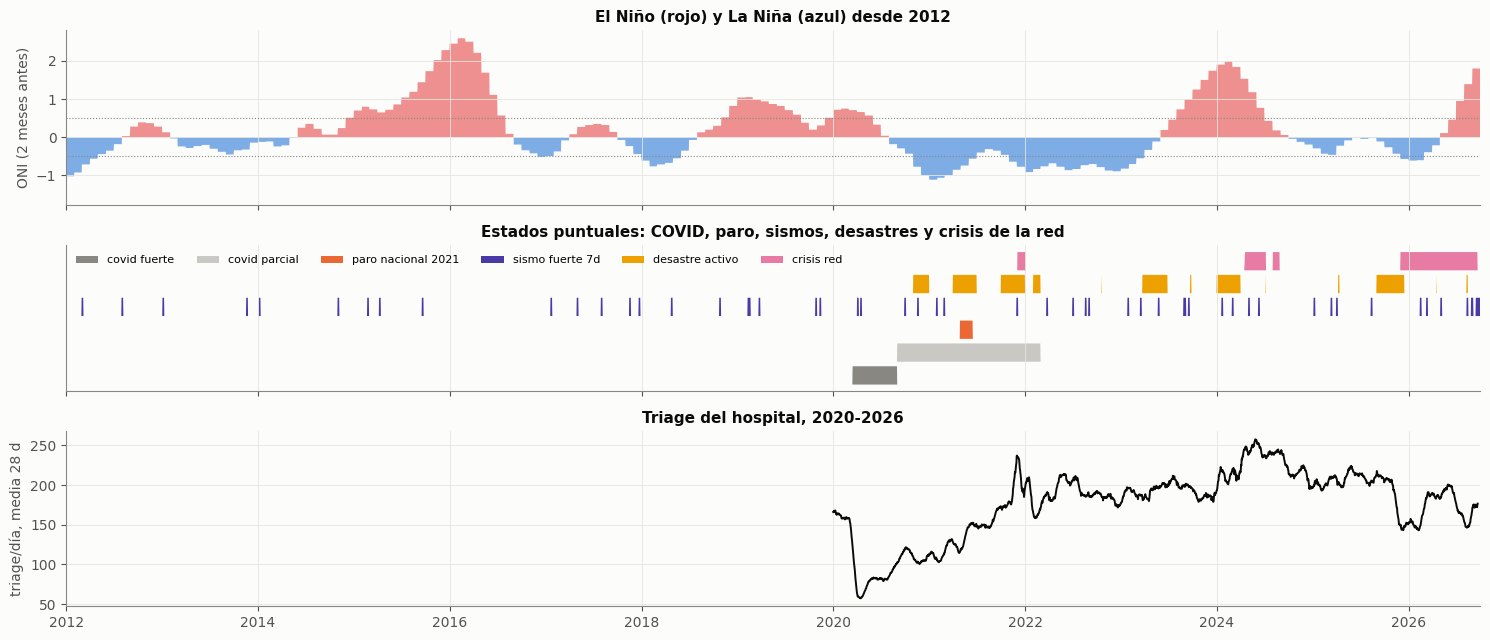

In [2]:
fig, axes = plt.subplots(3, 1, figsize=(15, 6.5), sharex=True, gridspec_kw={"height_ratios": [1.2, 1, 1.2]})
axes[0].fill_between(R.index, 0, R.oni, where=R.oni > 0, color=ROJO, alpha=.6, lw=0); axes[0].fill_between(R.index, 0, R.oni, where=R.oni < 0, color=AZUL, alpha=.6, lw=0)
axes[0].axhline(.5, color=MUDO, ls=":", lw=.8); axes[0].axhline(-.5, color=MUDO, ls=":", lw=.8); axes[0].set_ylabel("ONI (2 meses antes)"); axes[0].set_title("El Niño (rojo) y La Niña (azul) desde 2012")
for i, (e, c) in enumerate([("covid_fuerte", MUDO), ("covid_parcial", "#c9c8c4"), ("paro_nacional_2021", NARANJA), ("sismo_fuerte_7d", VIOLETA), ("desastre_activo", AMARILLO), ("crisis_red", MAGENTA)]):
    axes[1].fill_between(R.index, i, i + R[e].fillna(0) * .8, color=c, lw=0, label=e.replace("_", " "))
axes[1].set_yticks([]); axes[1].legend(ncol=6, fontsize=8, loc="upper left"); axes[1].set_title("Estados puntuales: COVID, paro, sismos, desastres y crisis de la red")
t = pd.read_parquet(RAIZ / "salidas/triage_diario.parquet").assign(dia=lambda d: pd.to_datetime(d.dia)).set_index("dia").triages
axes[2].plot(t.index, t.rolling(28, center=True, min_periods=14).mean(), color=TINTA, lw=1.4); axes[2].set_ylabel("triage/día, media 28 d")
axes[2].set_title("Triage del hospital, 2020-2026")
axes[2].set_xlim(pd.Timestamp("2012-01-01"), R.index[-1]); plt.tight_layout(); plt.show()

**Lectura.** El panel superior muestra que el índice ENSO alterna fases de varios meses o años, de modo que cada episodio ocupa una fracción grande de la serie y se confunde con la tendencia. El panel central ubica los estados puntuales: la COVID y el paro abren la ventana del hospital, los sismos y los desastres son marcas cortas y repartidas, y la crisis de la red se concentra desde 2025. El panel inferior pone el triage del hospital sobre las mismas fechas: el hundimiento de 2020, el ascenso hasta 2024 y la caída posterior. Ningún estado explica por sí solo esa forma, y por eso las secciones siguientes miden cada uno contra un control.

---
# 1. La COVID como régimen del triage

Es el único episodio de los estados anteriores que domina el entrenamiento, y se mide con el mismo rigor que los demás.

,días,triage/día,% del nivel desde 2022
antes,74,160.5,81.3
fuerte,170,79.2,40.1
parcial,546,144.0,72.9
después,1666,198.1,100.3


,días de entrenamiento,días COVID,% del entrenamiento
2024-12-31,1824,716,39.3
2025-12-31,2189,716,32.7
2026-09-13,2445,716,29.3


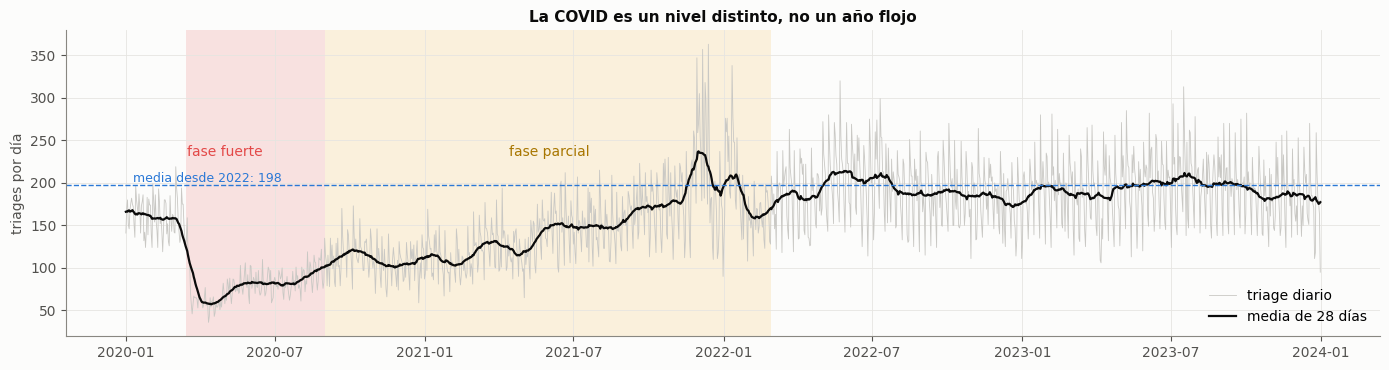

In [3]:
t = t.asfreq("D"); t.loc["2024-03-19":"2024-03-21"] = np.nan            # caída del registro: nulo, no cero
cv = (R.covid_fuerte + R.covid_parcial).reindex(t.index) > 0
fase = pd.Series("después", index=t.index); fase[R.covid_parcial.reindex(t.index) > 0] = "parcial"; fase[R.covid_fuerte.reindex(t.index) > 0] = "fuerte"
fase[t.index < "2020-03-15"] = "antes"
ref = t.loc["2022":].mean()
resumen = pd.DataFrame({"días": fase.value_counts(), "triage/día": t.groupby(fase).mean().round(1)}).loc[["antes", "fuerte", "parcial", "después"]]
resumen["% del nivel desde 2022"] = (100 * resumen["triage/día"] / ref).round(1)
peso = pd.DataFrame({o: {"días de entrenamiento": len(t.loc[:o].dropna()), "días COVID": int(cv.loc[:o].sum())} for o in ["2024-12-31", "2025-12-31", "2026-09-13"]}).T
peso["% del entrenamiento"] = (100 * peso["días COVID"] / peso["días de entrenamiento"]).round(1)
display(resumen); display(peso)
fig, ax = plt.subplots(figsize=(14, 3.8))
m28 = t.loc[:"2023"].rolling(28, center=True, min_periods=14).mean()
ax.plot(t.loc[:"2023"].index, t.loc[:"2023"], color="#c9c8c4", lw=.6, label="triage diario")
ax.plot(m28.index, m28, color=TINTA, lw=1.6, label="media de 28 días")
ax.axvspan(pd.Timestamp("2020-03-15"), pd.Timestamp("2020-08-31"), color=ROJO, alpha=.15, lw=0); ax.axvspan(pd.Timestamp("2020-09-01"), pd.Timestamp("2022-02-28"), color=AMARILLO, alpha=.12, lw=0)
ax.axhline(ref, color=AZUL, ls="--", lw=1); ax.text(pd.Timestamp("2020-01-10"), ref + 4, f"media desde 2022: {ref:.0f}", color=AZUL, fontsize=9)
ax.text(pd.Timestamp("2020-05-01"), 232, "fase fuerte", ha="center", color=ROJO); ax.text(pd.Timestamp("2021-06-01"), 232, "fase parcial", ha="center", color="#a87600")
ax.set_ylabel("triages por día"); ax.set_title("La COVID es un nivel distinto, no un año flojo"); ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

**Lectura.** La COVID no es un año flojo sino un nivel distinto. Antes de la fase fuerte el hospital registraba 160,5 triages por día; en la fase fuerte (170 días) bajó a 79,2, el 40,1 % del nivel posterior a 2022, y en la fase parcial (546 días) se mantuvo en 144,0, el 72,9 %, frente a 198,1 desde marzo de 2022. Esos 716 días pesan el 39,3 % del entrenamiento si el origen del modelo es el 31 de diciembre de 2024, el 32,7 % con origen al cierre de 2025 y el 29,3 % con origen en septiembre de 2026.

Dos cautelas. La primera es que marcar esos días como un nivel aparte es una decisión de modelado distinta de quitarlos: reducir su peso a un décimo empeoró la validación en los cuatro años probados, lo que indica que la forma semanal y anual de la fase parcial todavía aporta información. La segunda es que las dos fases son fechas fijas y la recuperación real fue gradual, de modo que la frontera del 1 de septiembre de 2020 es una convención.

---
# 2. Regímenes y enfermedades de la ciudad (2012-2024)

Con las familias de enfermedad de la vigilancia de Manizales se estimó el efecto de estar en cada estado, con mes fijo y
**tendencia lineal en lugar de año fijo** (un El Niño dura un año y el año fijo se lo comería). El efecto se
expresa en desviaciones típicas del índice de la familia; el punto marca los que sobreviven a la corrección
Benjamini-Hochberg (q < 0,10).

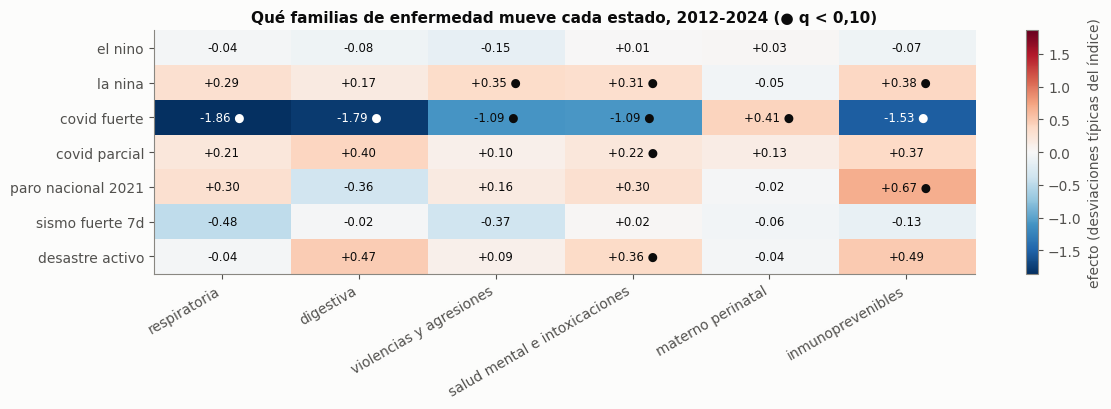

In [4]:
FAM = ix.familias_enfermedad().loc["2012":ix.REF_FIN]
W = R[ESTADOS].resample("W-SAT").mean(); W.index -= pd.Timedelta(days=6)
def efecto(y, X):
    filas = []; idx = y.dropna().index
    mes = pd.get_dummies(pd.Index(idx.month), prefix="m", drop_first=True).set_index(idx).astype(float)
    tend = pd.Series(np.arange(len(idx)) / 52, index=idx, name="tendencia")
    for c in X:
        D = pd.concat([y.rename("y"), X[c].rename("x"), mes, tend], axis=1).loc[idx].dropna()
        if D.x.std() == 0 or (D.x > 0).sum() < 4: continue
        r = sm.OLS(D.y, sm.add_constant(D.drop(columns="y"))).fit(cov_type="HAC", cov_kwds={"maxlags": 8})
        lo, hi = r.conf_int().loc["x"]
        filas.append({"estado": c, "efecto": r.params["x"], "lo": lo, "hi": hi, "p": r.pvalues["x"], "semanas en el estado": int((D.x > 0).sum())})
    T = pd.DataFrame(filas)
    if len(T): T["q"] = multipletests(T.p, method="fdr_bh")[1]
    return T
RF = {fam: efecto(FAM[fam], W.drop(columns=["crisis_red"])) for fam in FAM}
M = pd.DataFrame({fam: T.set_index("estado")["efecto"] for fam, T in RF.items()})
Q = pd.DataFrame({fam: T.set_index("estado")["q"] for fam, T in RF.items()})
fig, ax = plt.subplots(figsize=(12, 4.2))
v = np.nanmax(np.abs(M.values)); im = ax.imshow(M.values, cmap="RdBu_r", vmin=-v, vmax=v, aspect="auto")
ax.set_xticks(range(M.shape[1])); ax.set_xticklabels([c.replace("_", " ") for c in M.columns], rotation=30, ha="right")
ax.set_yticks(range(M.shape[0])); ax.set_yticklabels([i.replace("_", " ") for i in M.index]); ax.grid(False)
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        x = M.values[i, j]
        if not np.isnan(x): ax.text(j, i, f"{x:+.2f}" + (" ●" if Q.values[i, j] < .10 else ""), ha="center", va="center", fontsize=8.5, color="white" if abs(x) > v * .6 else TINTA)
plt.colorbar(im, ax=ax, label="efecto (desviaciones típicas del índice)"); ax.set_title("Qué familias de enfermedad mueve cada estado, 2012-2024 (● q < 0,10)"); plt.tight_layout(); plt.show()

**Lectura.** La Niña eleva la enfermedad de la ciudad: violencias y agresiones (+0,35 desviaciones típicas, q = 0,002), salud mental e intoxicaciones (+0,31, q = 0,018) e inmunoprevenibles, donde pesa la varicela (+0,38, q = 0,066), pasan la corrección de Benjamini-Hochberg. La respiratoria (+0,29) y la digestiva (+0,17) van en la misma dirección sin alcanzar el umbral. El Niño no mueve a ninguna familia de forma clara (efectos entre −0,15 y +0,03, q ≥ 0,22).

La COVID fuerte hunde cinco de las seis familias (−1,09 a −1,86 desviaciones típicas) y solo sube la materno-perinatal (+0,41): refleja menos consulta y menos notificación más que menos enfermedad, y es la razón por la que debe ir marcada. La fase parcial deja un residuo positivo en salud mental (+0,22). Los sismos no mueven a ninguna familia de forma significativa (q ≥ 0,11). Los desastres catalogados aparecen asociados a más salud mental (+0,36, q = 0,037) y el paro de 2021 a más inmunoprevenibles (+0,67, q = 0,066), con 75 semanas de desastre activo y 8 de paro en la muestra. Ninguna de las dos asociaciones resistió la comprobación del cuaderno 19. La del paro cae dentro de lo que produce una ventana de 8 semanas puesta al azar (un efecto igual o mayor en el 17,6 % de las posiciones) y los conteos crudos de varicela bajan durante el paro. La de los desastres descansa en un solo episodio, la alerta del volcán de 2023. Se leen como asociaciones que no se sostienen, no como hallazgos.

---
# 3. Regímenes y triage del hospital (2022-2024)

El desenlace es el triage semanal sin calendario ni escalones de la red, y el efecto se expresa en porcentaje del
triage con su intervalo de confianza al 95 %.

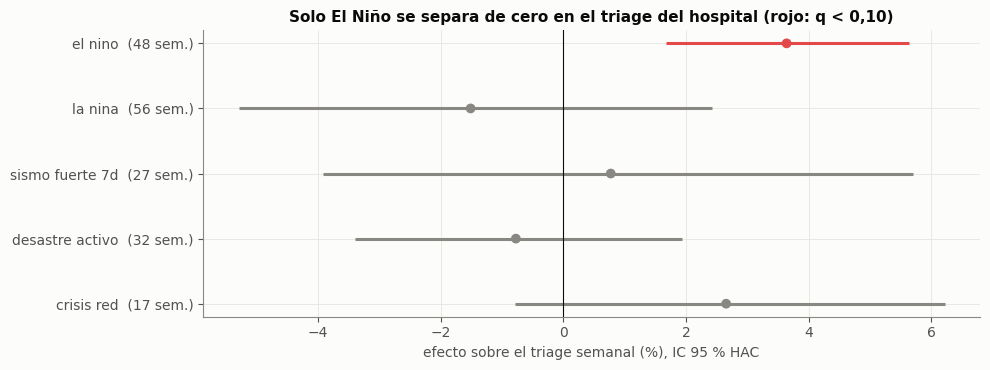

,estado,efecto %,lo %,hi %,p,q,semanas en el estado
0,el_nino,3.641,1.677,5.643,0.000,0.001,48
1,la_nina,-1.513,-5.299,2.424,0.446,0.713,56
2,sismo_fuerte_7d,0.773,-3.920,5.695,0.752,0.752,27
3,desastre_activo,-0.775,-3.406,1.928,0.571,0.713,32
4,crisis_red,2.655,-0.791,6.220,0.133,0.331,17


In [5]:
y = desenlace_semanal().y.loc[:ix.REF_FIN]
TH = efecto(y, W)
for c in ["efecto", "lo", "hi"]: TH[c + " %"] = 100 * (np.exp(TH[c]) - 1)
fig, ax = plt.subplots(figsize=(10, 3.8)); TT = TH.iloc[::-1].reset_index(drop=True)
col = [ROJO if q < .10 else MUDO for q in TT.q]
ax.hlines(TT.index, TT["lo %"], TT["hi %"], color=col, lw=2.2); ax.scatter(TT["efecto %"], TT.index, color=col, zorder=3, s=36)
ax.axvline(0, color=TINTA, lw=.8); ax.set_yticks(TT.index); ax.set_yticklabels([f"{e.replace('_', ' ')}  ({n} sem.)" for e, n in zip(TT.estado, TT["semanas en el estado"])])
ax.set_xlabel("efecto sobre el triage semanal (%), IC 95 % HAC"); ax.set_title("Solo El Niño se separa de cero en el triage del hospital (rojo: q < 0,10)"); plt.tight_layout(); plt.show()
TH[["estado", "efecto %", "lo %", "hi %", "p", "q", "semanas en el estado"]].round(3)

**Lectura.** Solo El Niño se separa de cero en el triage del hospital: +3,6 % (IC 95 % de +1,7 a +5,6 %; 48 semanas; q = 0,001). La Niña (−1,5 %), el sismo fuerte (+0,8 %) y el desastre activo (−0,8 %) tienen intervalos que incluyen el cero con holgura. La crisis de la red da +2,7 % (IC de −0,8 a +6,2 %), sin significancia, y su efecto ya lo recogen las variables de red del cuaderno 18.

La advertencia pesa tanto como el hallazgo. En la ventana 2022-2024 El Niño es **un solo episodio**, el de 2023-24, que coincide con 2024, el año de mayor volumen de la historia del hospital, y con el ascenso de SURA como aseguradora. La comparación cruda dentro de cada año no lo confirma de forma limpia (sección 7): en 2023 el triage con El Niño fue de 189,7 por día frente a 194,3 sin él, y en 2024, de 229,8 frente a 224,0. El +3,6 % es lo que queda después de controlar el mes y la tendencia lineal, no una diferencia visible en los promedios.

---
# 4. El terremoto del 10 de agosto de 2026 como episodio

Un evento único no tiene muestra para un coeficiente, pero sí se puede medir con un diseño de episodio: cada día posterior
al sismo se compara con la **mediana del mismo día de la semana en las 8 semanas anteriores**, sin festivos, vísperas,
puentes ni temporadas atípicas. Así el calendario queda controlado sin ajustar ningún modelo. Para saber si lo observado
es grande o es ruido, el mismo procedimiento se aplica a cada día de 2022-03 a 2026-07 como si fuera un sismo
(1.460 pseudoepisodios): esa distribución es la vara del azar. El sismo tuvo magnitud 7,4, epicentro en el Chocó y
profundidad intermedia; el catálogo de desastres registra para Manizales alerta roja y daños menores sin afectación
estructural en el hospital, que atendió heridos con áreas de expansión y canceló la consulta programada.

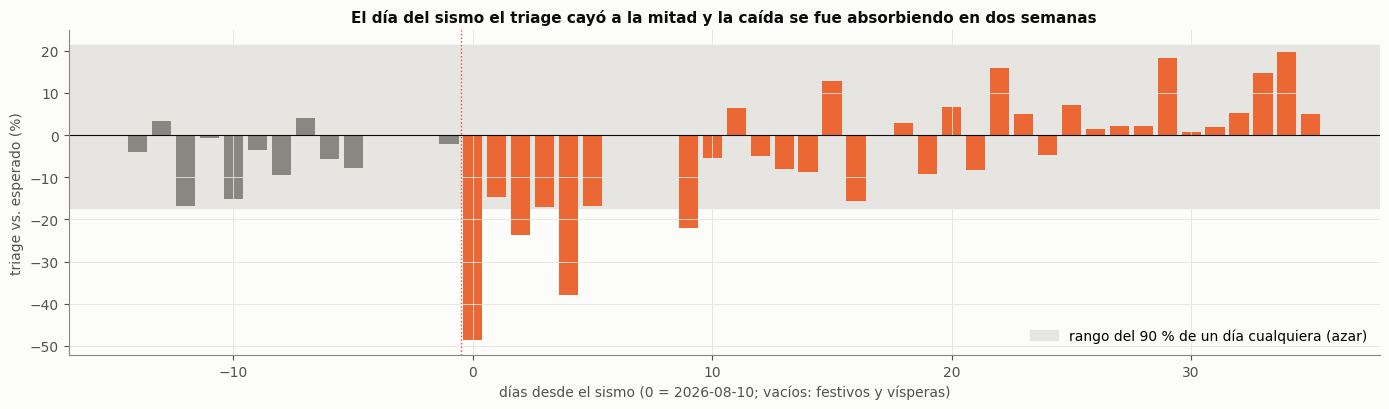

Percentil del sismo entre 1460 pseudoepisodios, días 1-7: 0.89 %  (media del azar +1.0 %, desv. 8.5 puntos)
Peor día de los 1238 pseudoepisodios (día 0): -37.9 %;  percentil 5 de un día cualquiera: -17.4 %


,día 0,días 1-7,días 8-21,días 0-13
%,-48.7,-22.3,-4.6,-18.7


,base de 4 semanas,base de 6 semanas,base de 8 semanas,base de 10 semanas
día 0,-48.7,-46.5,-48.7,-50.7
días 1-7,-20.1,-20.3,-22.3,-25.6
días 8-21,-2.3,-2.1,-4.6,-8.1


In [6]:
cal = pd.read_csv(RAIZ / "calendarios/calendario_Colombia.csv", parse_dates=["fecha"]).set_index("fecha")
atip = ((cal.es_festivo == 1) | (cal.es_vispera_festivo == 1) | (cal.es_post_festivo == 1) | (cal.es_puente == 1) | (cal.es_semana_santa == 1) | (cal.es_temporada_navidad == 1))
def _normal(idx): return ~atip.reindex(idx).fillna(False).values
def base(X, ev, semanas=8):
    # mediana por día de la semana de las `semanas` previas al evento, solo días normales (X: Series o DataFrame)
    pre = X.loc[ev - pd.Timedelta(days=7 * semanas):ev - pd.Timedelta(days=1)]; pre = pre[_normal(pre.index)]
    return pre.groupby(pre.index.dayofweek).median()
def rel(X, ev, ks, semanas=8):
    # cociente día/base - 1 para los días ev+k (X: Series); NaN en días atípicos o sin dato
    b = base(X, ev, semanas); out = {}
    for k in ks:
        d = ev + pd.Timedelta(days=k)
        ok = d in X.index and not atip.get(d, False) and d.dayofweek in b.index
        out[k] = (X.loc[d] / b.loc[d.dayofweek] - 1) if ok else np.nan
    return pd.Series(out)
def ventana(X, ev, a, b, semanas=8):
    # suma observada / suma esperada - 1 en los días normales de ev+a..ev+b (por columna si X es DataFrame)
    bs = base(X, ev, semanas); obs = esp = None
    for k in range(a, b + 1):
        d = ev + pd.Timedelta(days=k)
        if d not in X.index or atip.get(d, False) or d.dayofweek not in bs.index or np.all(pd.isna(X.loc[d])): continue
        o, e = X.loc[d], bs.loc[d.dayofweek]
        obs = o if obs is None else obs + o; esp = e if esp is None else esp + e
    return np.nan if obs is None else obs / esp - 1
EV = pd.Timestamp("2026-08-10")
PSEUDO = [d for d in pd.date_range("2022-03-01", "2026-07-15") if d.dayofweek < 7]
r_ev = rel(t, EV, range(-14, 36))
pl_dia = pd.Series({d: rel(t, d, [0])[0] for d in PSEUDO}).dropna()
lo5, hi95 = pl_dia.quantile(.05), pl_dia.quantile(.95)
fig, ax = plt.subplots(figsize=(14, 4.2))
ax.axhspan(100 * lo5, 100 * hi95, color="#e6e5e1", zorder=0, label="rango del 90 % de un día cualquiera (azar)")
cols = [NARANJA if k >= 0 else MUDO for k in r_ev.index]
ax.bar(r_ev.index, 100 * r_ev.values, color=cols, width=.8); ax.axhline(0, color=TINTA, lw=.8); ax.axvline(-.5, color=ROJO, ls=":", lw=1)
ax.set_xlabel("días desde el sismo (0 = 2026-08-10; vacíos: festivos y vísperas)"); ax.set_ylabel("triage vs. esperado (%)")
ax.set_title("El día del sismo el triage cayó a la mitad y la caída se fue absorbiendo en dos semanas"); ax.legend(loc="lower right"); plt.tight_layout(); plt.show()
resumen_ev = pd.Series({"día 0": r_ev[0], "días 1-7": ventana(t, EV, 1, 7), "días 8-21": ventana(t, EV, 8, 21), "días 0-13": ventana(t, EV, 0, 13)}) * 100
sens = pd.DataFrame({f"base de {w} semanas": {"día 0": 100 * rel(t, EV, [0], w)[0], "días 1-7": 100 * ventana(t, EV, 1, 7, w), "días 8-21": 100 * ventana(t, EV, 8, 21, w)} for w in (4, 6, 8, 10)})
pl_sem = pd.Series({d: ventana(t, d, 1, 7) for d in PSEUDO}).dropna()
print(f"Percentil del sismo entre {len(pl_sem)} pseudoepisodios, días 1-7: {100 * (pl_sem <= resumen_ev['días 1-7'] / 100).mean():.2f} %  (media del azar {100 * pl_sem.mean():+.1f} %, desv. {100 * pl_sem.std():.1f} puntos)")
print(f"Peor día de los {len(pl_dia)} pseudoepisodios (día 0): {100 * pl_dia.min():.1f} %;  percentil 5 de un día cualquiera: {100 * lo5:.1f} %")
display(resumen_ev.round(1).to_frame("%").T); display(sens.round(1))

**Lectura.** El día del sismo el triage fue un 48,7 % menor que el esperado para un lunes normal; entre los 1.238 días con dato que se evaluaron como pseudoepisodios, la peor caída fue de −37,9 % y el percentil 5 de un día cualquiera, de −17,4 %. El viernes 14 de agosto (día 4, −38,0 %) iguala esa peor caída del azar, y el resto de los días 1 a 5 quedan entre −14,6 y −23,7 %. En los días siguientes la demanda siguió por debajo: −22,3 % en promedio en los días 1 a 7 (martes a sábado; el domingo y el lunes festivo se excluyen), contra una media del azar de +1,0 % y una desviación de 8,5 puntos entre los 1.460 pseudoepisodios con primera semana evaluable. Solo el 0,89 % de ellos tuvo una primera semana igual o peor. Entre los días 8 y 21 el déficit casi desaparece (−4,6 %), y desde el día 22 las barras vuelven al rango del azar.

Con la ventana de dos semanas completas (días 0 a 13) la caída es de −18,7 %. Un ajuste anterior con modelo semanal dio −21,5 % a dos semanas y −26 % en la primera; los métodos son distintos (aquel controlaba el calendario con un modelo y este con la mediana del mismo día de la semana) y no se contrastaron día a día, pero coinciden en el orden de magnitud y en la forma: caída fuerte el primer día, déficit sostenido durante la primera semana y recuperación hacia la tercera. La sensibilidad a la longitud de la base es moderada: con 4 a 10 semanas el día 0 queda entre −46,5 y −50,7 % y la primera semana entre −20,1 y −25,6 %.

Un límite del diseño es que la red de salud tuvo otro escalón en julio de 2026 y la base de ocho semanas lo incluye parcialmente, lo que puede dejar la base algo alta y ampliar un poco el déficit, aunque no explica un día 0 de esta magnitud. Tampoco se distingue entre menos pacientes y menos registro: el catálogo de desastres señala que el hospital activó áreas de expansión y canceló la consulta programada ese día.

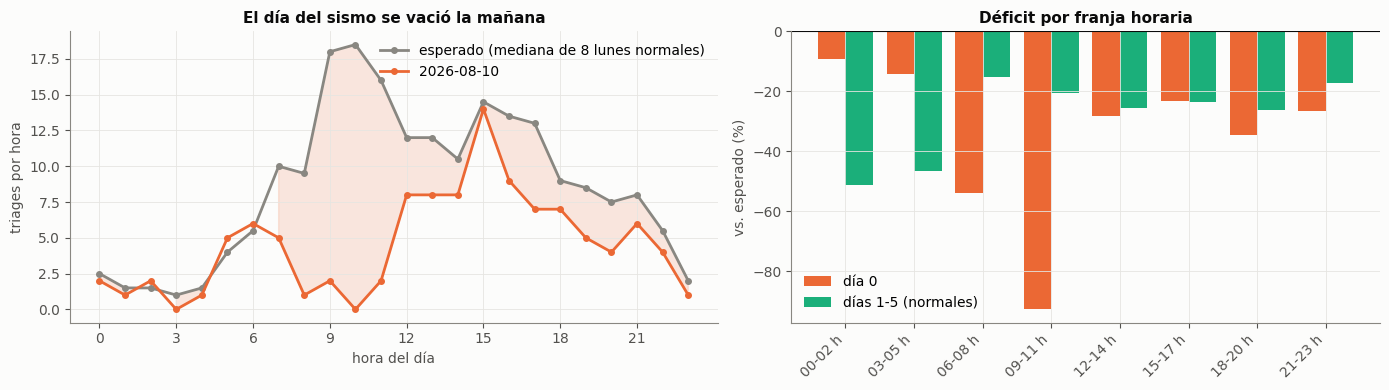

,00-02 h,03-05 h,06-08 h,09-11 h,12-14 h,15-17 h,18-20 h,21-23 h
esperado,5.5,6.5,25.0,52.5,34.5,41.0,25.0,15.5
observado,5.0,6.0,12.0,4.0,24.0,30.0,16.0,11.0


In [7]:
h = pd.read_parquet(RAIZ / "salidas/triage_horario.parquet").assign(dia=lambda d: pd.to_datetime(d.dia))
H = h.pivot_table(index="dia", columns="hora", values="triages", aggfunc="sum").reindex(t.index).fillna(0); H[t.isna()] = np.nan
BLQ = {f"{a:02d}-{a + 2:02d} h": list(range(a, a + 3)) for a in range(0, 24, 3)}
HB = pd.DataFrame({k: H[v].sum(axis=1) for k, v in BLQ.items()})
b0 = base(H, EV).loc[EV.dayofweek]
fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]; ax.plot(range(24), b0.values, color=MUDO, lw=2, marker="o", ms=4, label="esperado (mediana de 8 lunes normales)")
ax.plot(range(24), H.loc[EV].values, color=NARANJA, lw=2, marker="o", ms=4, label="2026-08-10"); ax.fill_between(range(24), b0.values, H.loc[EV].values, where=H.loc[EV].values < b0.values, color=NARANJA, alpha=.15)
ax.set_xlabel("hora del día"); ax.set_ylabel("triages por hora"); ax.set_xticks(range(0, 24, 3)); ax.set_title("El día del sismo se vació la mañana"); ax.legend()
rb = pd.DataFrame({"día 0": ventana(HB, EV, 0, 0), "días 1-5": ventana(HB, EV, 1, 5)}) * 100
ax = axes[1]; x = np.arange(len(rb)); ax.bar(x - .2, rb["día 0"], .4, color=NARANJA, label="día 0"); ax.bar(x + .2, rb["días 1-5"], .4, color=AQUA, label="días 1-5 (normales)")
ax.set_xticks(x); ax.set_xticklabels(rb.index, rotation=45, ha="right"); ax.axhline(0, color=TINTA, lw=.8); ax.set_ylabel("vs. esperado (%)"); ax.set_title("Déficit por franja horaria"); ax.legend(); plt.tight_layout(); plt.show()
cnt = pd.DataFrame({"esperado": b0.groupby(np.arange(24) // 3).sum().values, "observado": H.loc[EV].groupby(np.arange(24) // 3).sum().values}, index=rb.index).round(1).T
cnt

**Lectura.** La firma horaria del día 0 no es una caída pareja. En el bloque de 9 a 11 h se registraron 4 triages donde se esperaban 52,5 (−92,5 %) y en el de 6 a 8 h, 12 frente a 25 (−53,8 %), mientras que el bloque nocturno de 0 a 5 h quedó casi intacto (−9 y −14 %, con apenas 5 a 6 triages esperados por bloque). Por la tarde la demanda se recuperó parcialmente: de 15 a 17 h hubo 30 triages frente a 41 esperados (−23,1 %). El vaciado se concentra en las horas de mayor demanda de un día laboral.

En los días 1 a 5 el déficit se reparte por todo el día, con cifras mayores en la madrugada (−51 % de 0 a 2 h y −46 % de 3 a 5 h), pero esos bloques tienen pocos triages esperados y el porcentaje es poco fiable. La figura describe cuándo cayó el registro, no cuándo ocurrió el sismo: los agregados no distinguen entre pacientes que no vinieron y pacientes que no se registraron.

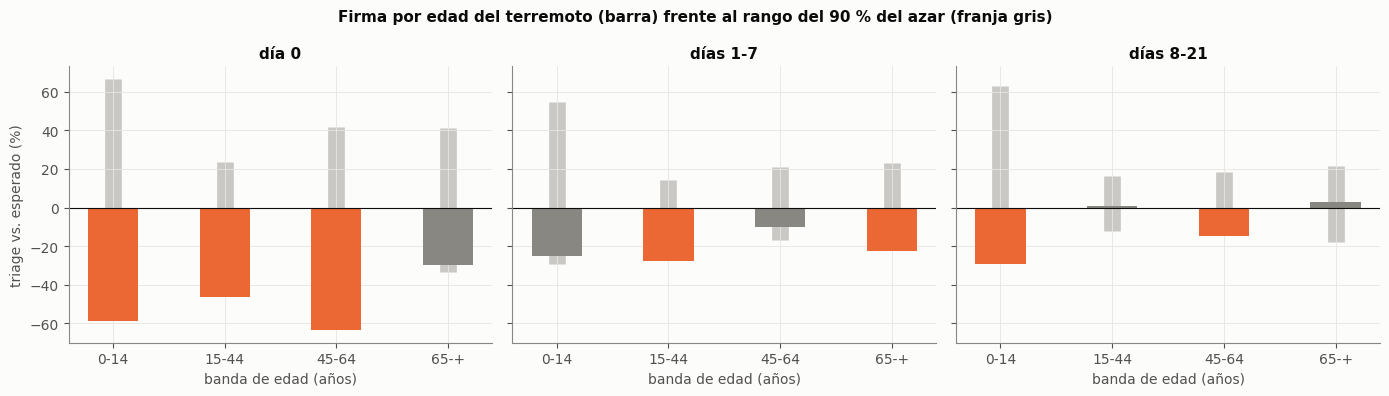

,día 0,días 1-7,días 8-21,triages/día normal (8 sem. previas)
banda,,,,
0-14,-58.8,-25.0,-29.6,14.7
15-44,-46.5,-27.6,0.6,88.4
45-64,-63.6,-10.2,-14.8,31.5
65-+,-30.0,-22.4,2.6,34.2


Dos semanas (días 0-13), 0-14 años: -29.1  %;  total: -18.7  %


In [8]:
E = pd.read_parquet(RAIZ / "salidas/triage_edad.parquet").assign(dia=lambda d: pd.to_datetime(d.dia)).pivot_table(index="dia", columns="banda", values="n", aggfunc="sum").reindex(t.index).fillna(0)
E[t.isna()] = np.nan; E = E[["0-4", "5-14", "15-44", "45-64", "65-+"]]; E["0-14"] = E["0-4"] + E["5-14"]
BANDAS = ["0-14", "15-44", "45-64", "65-+"]; VENT = [("día 0", 0, 0), ("días 1-7", 1, 7), ("días 8-21", 8, 21)]
pse_e = {nm: pd.DataFrame({d: ventana(E[BANDAS], d, a, b) for d in PSEUDO[::2]}).T.dropna() for nm, a, b in VENT}
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, (nm, a, b) in zip(axes, VENT):
    obs = 100 * ventana(E[BANDAS], EV, a, b); q5 = 100 * pse_e[nm].quantile(.05); q95 = 100 * pse_e[nm].quantile(.95)
    for i, bd in enumerate(BANDAS): ax.vlines(i, q5[bd], q95[bd], color="#c9c8c4", lw=12, zorder=0)
    ax.bar(range(len(BANDAS)), obs.values, width=.45, color=[NARANJA if o < q5[bd] else MUDO for o, bd in zip(obs.values, BANDAS)], zorder=2)
    ax.axhline(0, color=TINTA, lw=.8); ax.set_xticks(range(len(BANDAS))); ax.set_xticklabels(BANDAS); ax.set_title(nm); ax.set_xlabel("banda de edad (años)")
axes[0].set_ylabel("triage vs. esperado (%)"); fig.suptitle("Firma por edad del terremoto (barra) frente al rango del 90 % del azar (franja gris)", fontsize=11, fontweight="bold", color=TINTA); plt.tight_layout(); plt.show()
n_ed = pd.DataFrame({nm: ventana(E[BANDAS], EV, a, b) * 100 for nm, a, b in VENT}).round(1)
vol = pd.DataFrame({"triages/día normal (8 sem. previas)": [base(E[bd], EV).mean() for bd in BANDAS]}, index=BANDAS).round(1)
display(n_ed.join(vol)); print("Dos semanas (días 0-13), 0-14 años:", round(100 * ventana(E[["0-14"]], EV, 0, 13)["0-14"], 1), " %;  total:", round(100 * ventana(t, EV, 0, 13), 1), " %")

**Lectura.** El día 0 la caída supera el rango del 90 % del azar en tres bandas: −58,8 % en 0 a 14 años, −46,5 % en 15 a 44 y −63,6 % en 45 a 64. La de 65 o más (−30,0 %) cae también, pero queda dentro de lo que el azar produce (límite de −33,3 %). En la primera semana solo 15 a 44 (−27,6 %) y 65 o más (−22,4 %) quedan fuera del rango del azar; las otras dos bandas siguen por debajo, pero dentro de él.

Entre los días 8 y 21 las bandas de 15 a 44 (+0,6 %) y 65 o más (+2,6 %) vuelven a la base, mientras que 0 a 14 años (−29,6 %) y 45 a 64 (−14,8 %) quedan apenas por debajo del percentil 5 del azar (−26,5 % y −14,3 %). Con dos semanas completas la banda de 0 a 14 años cae −29,1 % frente a −18,7 % del total. Es una pista coherente con una consulta infantil que tarda más en volver, pero esa banda tiene 14,7 triages por día, el intervalo es ancho y el margen sobre el azar es pequeño; se lee como una hipótesis sobre un episodio único.

---
# 5. Los sismos fuertes como clase de eventos (2020-2026)

El terremoto es excepcional. Lo que sí se repite son los sismos de M ≥ 4,5 a menos de 150 km, y con ellos hay muestra
suficiente. Cada uno se trata como un episodio con el mismo diseño de la sección anterior y se promedian las curvas.

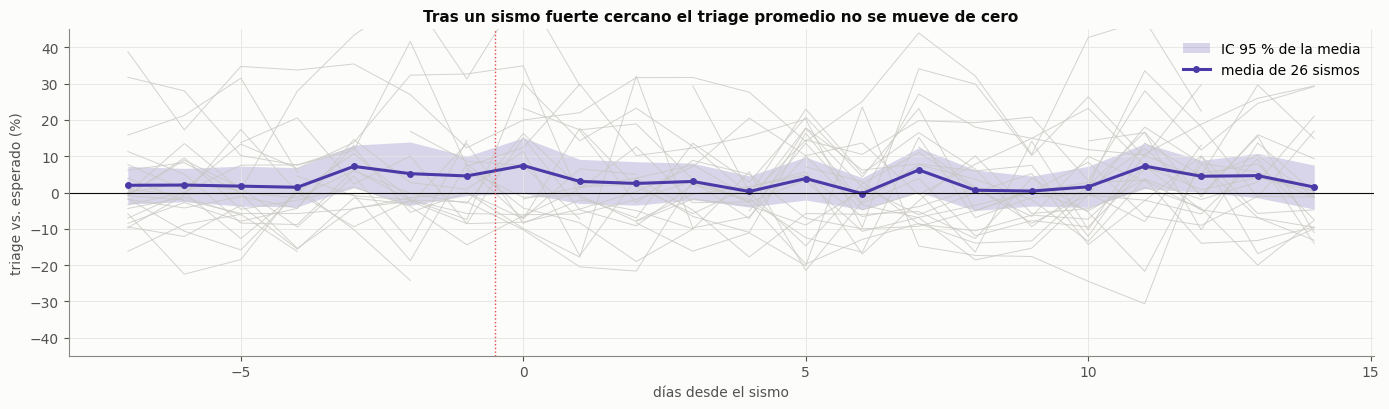

26 sismos; día 0: media +7.4 % (IC95 -0.2 a +15.1); días 1-7: media +3.5 % (IC95 -0.5 a +7.4), mediana -0.1 %


,fecha,mag,place,día 0 (%),días 1-7 (%)
71,2023-08-27,5.7,"5 km E of El Cantón de San Pablo, Colombia",-6.1,-0.0
77,2024-01-19,5.6,"7 km E of Cartago, Colombia",34.9,8.6
73,2023-09-14,5.2,"9 km S of El Cantón de San Pablo, Colombia",-6.4,-1.4
72,2023-08-31,4.9,"2 km NNE of Istmina, Colombia",-7.2,0.1
58,2021-01-27,4.9,"8 km NNW of Caicedonia, Colombia",-10.3,-13.2


In [9]:
sis = pd.read_csv(RAIZ / "calendarios/sismos_usgs.csv", parse_dates=["fecha"])
sis = sis[(sis.mag >= 4.5) & (sis.fecha >= "2020-04-15") & (sis.fecha != "2026-08-10") & (sis.fecha <= "2026-08-09")]
fechas = sorted(sis.fecha.unique()); KS = range(-7, 15)
MS = pd.DataFrame({pd.Timestamp(d): rel(t, pd.Timestamp(d), KS) for d in fechas}).T
mu = MS.mean(); se = MS.std() / np.sqrt(MS.count()); n = MS.count()
fig, ax = plt.subplots(figsize=(14, 4.2))
for _, f in MS.iterrows(): ax.plot(MS.columns, 100 * f.values, color="#c9c8c4", lw=.7, alpha=.8)
ax.fill_between(MS.columns, 100 * (mu - 1.96 * se), 100 * (mu + 1.96 * se), color=VIOLETA, alpha=.2, lw=0, label="IC 95 % de la media")
ax.plot(MS.columns, 100 * mu, color=VIOLETA, lw=2.2, marker="o", ms=4, label=f"media de {len(MS)} sismos"); ax.axhline(0, color=TINTA, lw=.8); ax.axvline(-.5, color=ROJO, ls=":", lw=1)
ax.set_ylim(-45, 45); ax.set_xlabel("días desde el sismo"); ax.set_ylabel("triage vs. esperado (%)"); ax.set_title("Tras un sismo fuerte cercano el triage promedio no se mueve de cero"); ax.legend(loc="upper right"); plt.tight_layout(); plt.show()
sem1 = pd.Series({pd.Timestamp(d): ventana(t, pd.Timestamp(d), 1, 7) for d in fechas}).dropna(); dia0 = MS[0].dropna()
mag = sis.set_index("fecha").mag
print(f"{len(MS)} sismos; día 0: media {100 * dia0.mean():+.1f} % (IC95 {100 * (dia0.mean() - 1.96 * dia0.std() / np.sqrt(len(dia0))):+.1f} a {100 * (dia0.mean() + 1.96 * dia0.std() / np.sqrt(len(dia0))):+.1f}); "
      f"días 1-7: media {100 * sem1.mean():+.1f} % (IC95 {100 * (sem1.mean() - 1.96 * sem1.std() / np.sqrt(len(sem1))):+.1f} a {100 * (sem1.mean() + 1.96 * sem1.std() / np.sqrt(len(sem1))):+.1f}), mediana {100 * sem1.median():+.1f} %")
fuertes = sis.sort_values("mag", ascending=False).head(5).assign(dia0=lambda d: [100 * rel(t, pd.Timestamp(f), [0])[0] for f in d.fecha], d1_7=lambda d: [100 * ventana(t, pd.Timestamp(f), 1, 7) for f in d.fecha])
fuertes[["fecha", "mag", "place", "dia0", "d1_7"]].assign(place=lambda d: d.place.str.replace("�", "")).round(1).rename(columns={"dia0": "día 0 (%)", "d1_7": "días 1-7 (%)"})

**Lectura.** Con 26 sismos de M ≥ 4,5 a menos de 150 km entre abril de 2020 y el día anterior al terremoto, la media del triage no se separa de cero después de un sismo: en el día 0 es +7,4 % (IC 95 % de −0,2 a +15,1 %) y en los días 1 a 7, +3,5 % (IC de −0,5 a +7,4 %), con medianas de −1,3 % y −0,1 %. El signo positivo de la media lo producen pocos episodios con desvíos grandes (+56,3 % el 2021-11-29 y +34,9 % el 2024-01-19), que la mediana no comparte; ningún episodio cae por debajo de −10,3 % el día 0. El de mayor magnitud (M 5,7, Chocó, 2023-08-27) quedó en −6,1 % el día 0 y −0,0 % la primera semana; el más cercano (M 5,6 en Cartago, a unos 51 km) subió, y su día 0 puede estar inflado porque la base de enero se calcula con pocas semanas normales tras excluir las de fin de año.

Ninguno de los 26 sismos previos reproduce un efecto como el del terremoto de 2026, de modo que para esta clase de eventos el resultado negativo es consistente. Lo que no se puede concluir es que un sismo muy fuerte y cercano no mueva la demanda: los 26 episodios son de magnitud moderada y profundidad intermedia, y con una media de 26 episodios el intervalo mide unos ±4 puntos, por lo que un efecto menor o limitado a pocos episodios no se vería. El terremoto de 2026 es de otra clase y se trató aparte en la sección anterior.

---
# 6. El paro nacional de 2021 y los desastres de la ciudad

Mismo diseño de episodio. El paro se mide desde su inicio (2021-04-28) con ventana larga, porque duró siete semanas y
ocurrió dentro de la fase parcial de la COVID. Los desastres con fecha exacta se miran uno por uno; el
deslizamiento del barrio Centenario (febrero de 2022, tres fallecidos) no tiene día exacto en el catálogo y por eso no
se puede medir como episodio.

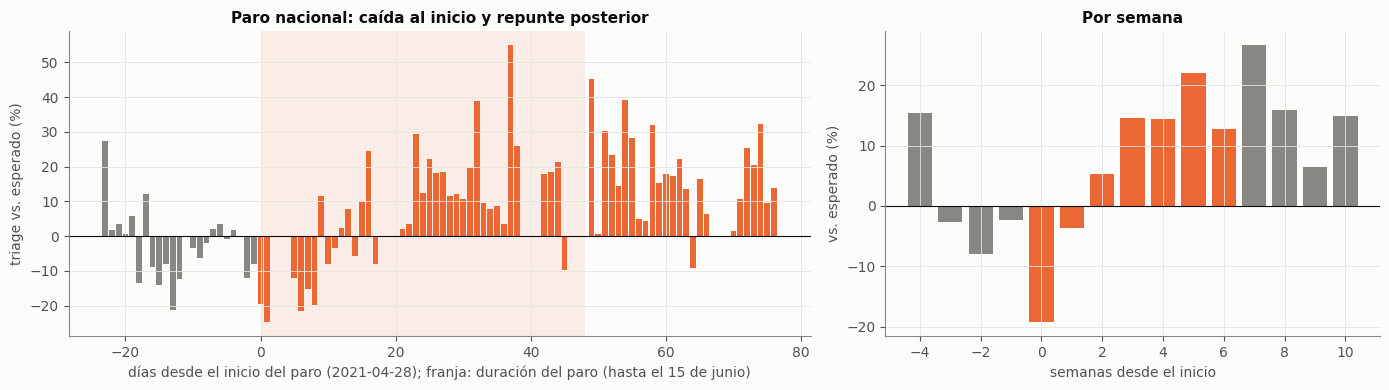

Paro, semana 0: -19.3 %; semanas 1-2: -0.4 %; semanas 4-6: +16.0 %.  Azar en la COVID (ventanas de 14 días, oct-2020 a ene-2022): media +7.0 %, 5-95 %: -12.2 a +25.4 %


In [10]:
PARO = pd.Timestamp("2021-04-28")
rp = rel(t, PARO, range(-28, 77)); sem = pd.Series({k: ventana(t, PARO, 7 * k, 7 * k + 6) for k in range(-4, 11)})
pl_par = pd.Series({d: ventana(t, d, 0, 13) for d in pd.date_range("2020-10-01", "2022-01-01")}).dropna()
fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]; ax.axvspan(0, 48, color=NARANJA, alpha=.1, lw=0); ax.bar(rp.index, 100 * rp.values, color=[NARANJA if k >= 0 else MUDO for k in rp.index], width=.85); ax.axhline(0, color=TINTA, lw=.8)
ax.set_xlabel("días desde el inicio del paro (2021-04-28); franja: duración del paro (hasta el 15 de junio)"); ax.set_ylabel("triage vs. esperado (%)"); ax.set_title("Paro nacional: caída al inicio y repunte posterior")
ax = axes[1]; ax.bar(sem.index, 100 * sem.values, color=[NARANJA if 0 <= k <= 6 else MUDO for k in sem.index]); ax.axhline(0, color=TINTA, lw=.8); ax.set_xlabel("semanas desde el inicio"); ax.set_ylabel("vs. esperado (%)"); ax.set_title("Por semana"); plt.tight_layout(); plt.show()
print(f"Paro, semana 0: {100 * sem[0]:+.1f} %; semanas 1-2: {100 * ventana(t, PARO, 7, 20):+.1f} %; semanas 4-6: {100 * ventana(t, PARO, 28, 48):+.1f} %.  Azar en la COVID (ventanas de 14 días, oct-2020 a ene-2022): media {100 * pl_par.mean():+.1f} %, 5-95 %: {100 * pl_par.quantile(.05):+.1f} a {100 * pl_par.quantile(.95):+.1f} %")

**Lectura.** La semana de inicio del paro el triage fue un 19,3 % menor que el esperado, por debajo del rango del 90 % que muestran las ventanas de dos semanas tomadas al azar dentro de la COVID (de −12,2 % a +25,4 %, con media de +7,0 % porque ese periodo venía de recuperación). Las semanas 1 y 2 vuelven a la base (−0,4 %) y entre las semanas 4 y 6 el triage queda un 16,0 % por encima, algo que ese azar produce con facilidad. El repunte no se detiene el 15 de junio: sigue por encima de la base hasta la semana 10 (figura derecha), lo que apunta a la recuperación de la demanda tras la fase fuerte y no al paro.

Este episodio no se puede separar de la COVID: el paro cae dentro de la fase parcial, con una demanda en recuperación y oleadas de contagio, y la base de ocho semanas previas refleja esa tendencia. La caída inicial es compatible con una ciudad bloqueada, pero también con el estado de la pandemia, y el diseño no tiene un grupo de comparación que permita distinguirlos. El paro queda como marca, no como efecto estimado.

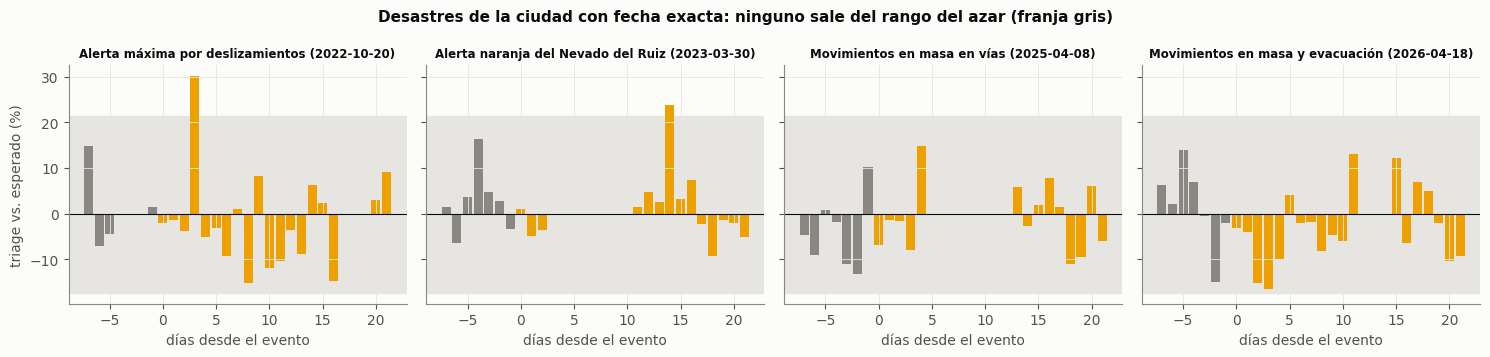

,día 0,días 1-7,días 8-21
Alerta máxima por deslizamientos (2022-10-20),-2.1,-0.6,-3.2
Alerta naranja del Nevado del Ruiz (2023-03-30),1.0,-4.3,1.8
Movimientos en masa en vías (2025-04-08),-6.9,0.1,0.1
Movimientos en masa y evacuación (2026-04-18),-3.1,-7.1,-1.0


In [11]:
DES = {"Alerta máxima por deslizamientos (2022-10-20)": "2022-10-20", "Alerta naranja del Nevado del Ruiz (2023-03-30)": "2023-03-30",
       "Movimientos en masa en vías (2025-04-08)": "2025-04-08", "Movimientos en masa y evacuación (2026-04-18)": "2026-04-18"}
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
for ax, (nm, d) in zip(axes, DES.items()):
    d = pd.Timestamp(d); r = rel(t, d, range(-7, 22)); ax.bar(r.index, 100 * r.values, color=[AMARILLO if k >= 0 else MUDO for k in r.index], width=.85)
    ax.axhspan(100 * lo5, 100 * hi95, color="#e6e5e1", zorder=0); ax.axhline(0, color=TINTA, lw=.8); ax.set_title(nm, fontsize=8.5); ax.set_xlabel("días desde el evento")
axes[0].set_ylabel("triage vs. esperado (%)"); fig.suptitle("Desastres de la ciudad con fecha exacta: ninguno sale del rango del azar (franja gris)", fontsize=11, fontweight="bold", color=TINTA); plt.tight_layout(); plt.show()
filas = {nm: {"día 0": 100 * rel(t, pd.Timestamp(d), [0])[0], "días 1-7": 100 * ventana(t, pd.Timestamp(d), 1, 7), "días 8-21": 100 * ventana(t, pd.Timestamp(d), 8, 21)} for nm, d in DES.items()}
pd.DataFrame(filas).T.round(1)

**Lectura.** Ninguno de los cuatro desastres con fecha exacta saca el triage del rango del azar: el día 0 va de −6,9 % a +1,0 %, la primera semana de −7,1 % a +0,1 % y los días 8 a 21 de −3,2 % a +1,8 %. La alerta naranja del Nevado del Ruiz, que duró 89 días, tampoco deja un cambio en la semana en que empezó. El resultado coincide con el de la ciudad (sección 2): los deslizamientos no mueven la enfermedad notificada, y la asociación de los desastres en conjunto con más salud mental descansa en un solo episodio, la alerta del volcán de 2023 (cuaderno 19).

Estos eventos afectaron sectores y vías concretos, no la operación de toda la ciudad. El hallazgo no descarta efectos en subgrupos pequeños (traumatismos, salud mental, barrios afectados) que el agregado por día no puede ver. El deslizamiento de Centenario (febrero de 2022, tres fallecidos) no tiene día exacto en el catálogo y no se pudo medir como episodio.

---
# 7. El Niño como hipótesis prospectiva

El Niño es el único estado que se separa de cero en el triage del hospital, y su evidencia es un solo episodio. La
sección 3 lo mostró; aquí se pone el episodio en contexto: el índice, su coincidencia con el pico de volumen y lo que
hoy está en curso.

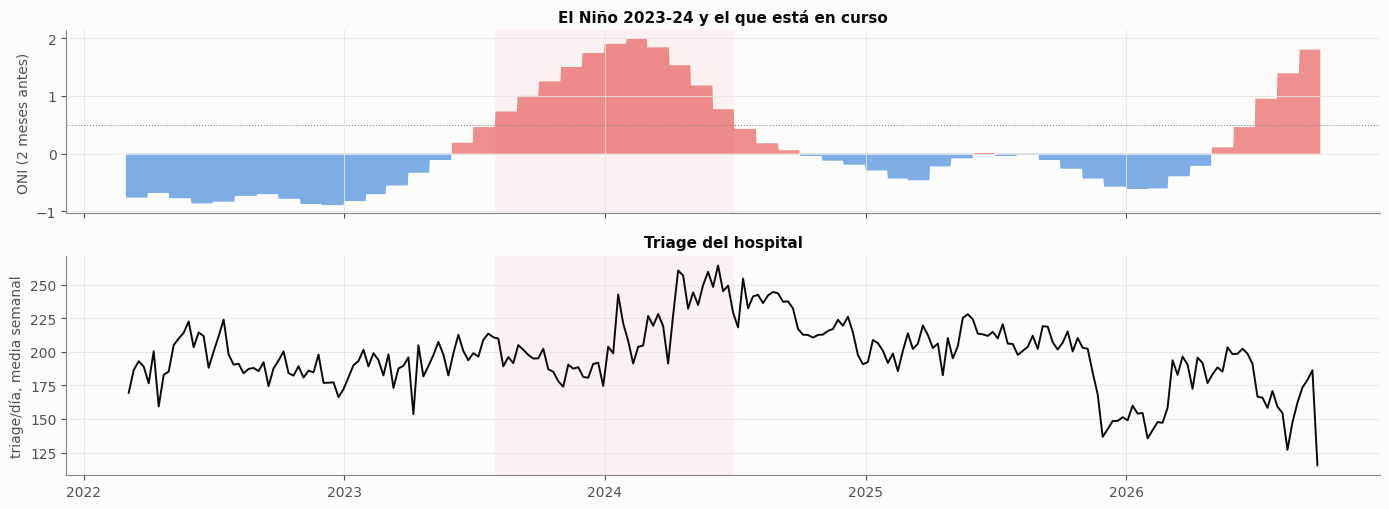

el_nino,El Niño,sin El Niño
dia,,
2022,NaN,189.6
2023,189.7,194.3
2024,229.8,224.0
2025,NaN,199.6
2026,160.8,177.6


,fecha,trimestre,anio,oni,fase
917,2026-06-15,MJJ,2026,1.39,el_nino_en_curso
918,2026-07-15,JJA,2026,1.80,el_nino_en_curso
919,2026-08-15,JAS,2026,2.16,el_nino_en_curso


In [12]:
sem_t = t.resample("W-SAT").mean().loc["2022-03":"2026-09"]
fig, axes = plt.subplots(2, 1, figsize=(14, 5.2), sharex=True, gridspec_kw={"height_ratios": [1, 1.2]})
o = R.oni.loc["2022-03":"2026-09"]; axes[0].fill_between(o.index, 0, o, where=o > 0, color=ROJO, alpha=.6, lw=0); axes[0].fill_between(o.index, 0, o, where=o < 0, color=AZUL, alpha=.6, lw=0)
axes[0].axhline(.5, color=MUDO, ls=":", lw=.8); axes[0].set_ylabel("ONI (2 meses antes)"); axes[0].set_title("El Niño 2023-24 y el que está en curso")
axes[1].plot(sem_t.index, sem_t, color=TINTA, lw=1.4); axes[1].set_ylabel("triage/día, media semanal"); axes[1].set_title("Triage del hospital")
for ax in axes: ax.axvspan(pd.Timestamp("2023-08-01"), pd.Timestamp("2024-06-30"), color=ROJO, alpha=.06, lw=0)
plt.tight_layout(); plt.show()
anual = t.groupby([t.index.year, R.el_nino.reindex(t.index).map({1.0: "El Niño", 0.0: "sin El Niño"})]).mean().unstack().round(1).loc[2022:]
display(anual)
pd.read_csv(RAIZ / "calendarios/enso_oni.csv").tail(3)

**Lectura.** La figura superior sitúa los episodios: El Niño de 2023-24, activo en el estado diario entre agosto de 2023 y junio de 2024 (con el rezago de dos meses del índice), y el que está en curso desde julio de 2026, con un ONI de +2,16 en agosto-septiembre, por encima del máximo de 2023-24 (+1,99, en febrero de 2024). Debajo, el triage semanal tuvo su máximo en 2024. La tabla por año muestra por qué la señal de +3,6 % es frágil: 2025 no tiene días con El Niño, y en 2026 los días con El Niño tienen un triage menor (160,8) que los demás (177,6), porque ese año el nivel lo gobierna la caída de Nueva EPS y no el clima.

La hipótesis que queda es prospectiva y se puede refutar: con un El Niño fuerte en curso, entre el 4 de octubre y el 26 de diciembre de 2026 el triage real debería superar en 2 % o más, en promedio, a la mediana de la combinación congelada de modelos, que no usa el índice ENSO. Si no lo supera, la hipótesis se rechaza. Es posible además que la firma del «día soleado y cálido» de 2022-2024 que muestran los cuadernos 12 y 14, y que desapareció en 2025, fuera este mismo episodio.

---
# 8. Conclusiones y límites

**Conclusiones.**

1. **Los regímenes se pueden tratar como estados diarios conocidos al predecir** (El Niño, La Niña, COVID fuerte y parcial, paro, sismo fuerte, desastre activo y crisis de la red). La COVID y el paro pasaron una sola vez, así que entran como marcas y no como predictores.
2. **La COVID es un nivel distinto**: 79,2 triages por día en la fase fuerte y 144,0 en la parcial frente a 198,1 desde 2022, y sus 716 días ocupan entre el 29 y el 39 % del entrenamiento según el origen.
3. **El terremoto de 2026 es el único evento que deja una huella clara en el hospital**: −48,7 % el día 0, −22,3 % la primera semana y −4,6 % entre los días 8 y 21, con el vaciado concentrado de 6 a 11 h y una caída mayor que el azar el día 0 en tres de las cuatro bandas de edad. La banda de 0 a 14 años tarda más en recuperarse (−29,6 % entre los días 8 y 21, en el borde del rango del azar).
4. **Los sismos fuertes de magnitud moderada, el paro y los desastres de la ciudad no se distinguen del azar** en el triage: 26 sismos con media de +3,5 % la primera semana (IC de −0,5 a +7,4 %) y cuatro desastres sin ningún valor fuera del rango del azar. El paro no se puede separar de la COVID.
5. **La Niña eleva la enfermedad de la ciudad** (violencias, salud mental e inmunoprevenibles, tras corregir pruebas múltiples) pero no el triage del hospital (−1,5 %, IC de −5,3 a +2,4 %).
6. **El Niño es la hipótesis más interesante para el hospital**: +3,6 % (IC de +1,7 a +5,6 %) en un único episodio, que no se separa del año de mayor volumen ni de la entrada de SURA. Se contrasta de forma prospectiva con el episodio en curso.

**Límites.** Los diseños de episodio comparan con la mediana del mismo día de la semana en las ocho semanas previas y no incorporan clima ni red de salud; el escalón de la red de julio de 2026 puede inflar algo el déficit del terremoto. Los agregados diarios no distinguen menos pacientes de menos registro, y por edad y por hora las cifras esperadas son pequeñas. Con uno o dos episodios por ventana, el peso de estos estados en un modelo tiene que venir de métodos que se frenan solos (regularización, árboles poco profundos), o se sobreajustan. En el modelo entran la fase ENSO con su intensidad, la marca de COVID y la de sismo fuerte; desastre y crisis de la red ya están cubiertos por las variables de red.